# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [2]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [5]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [6]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [7]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

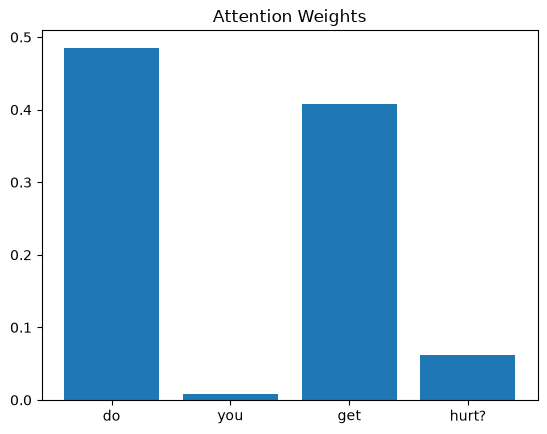

In [9]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question 1: do you get hurt?
Highest-attention word: 'do' (weight=0.4851)
Question 85: who is your momma?
Highest-attention word: 'is' (weight=0.4881)
Question 168: that was a pretty genius answer
Highest-attention word: 'that' (weight=0.2560)


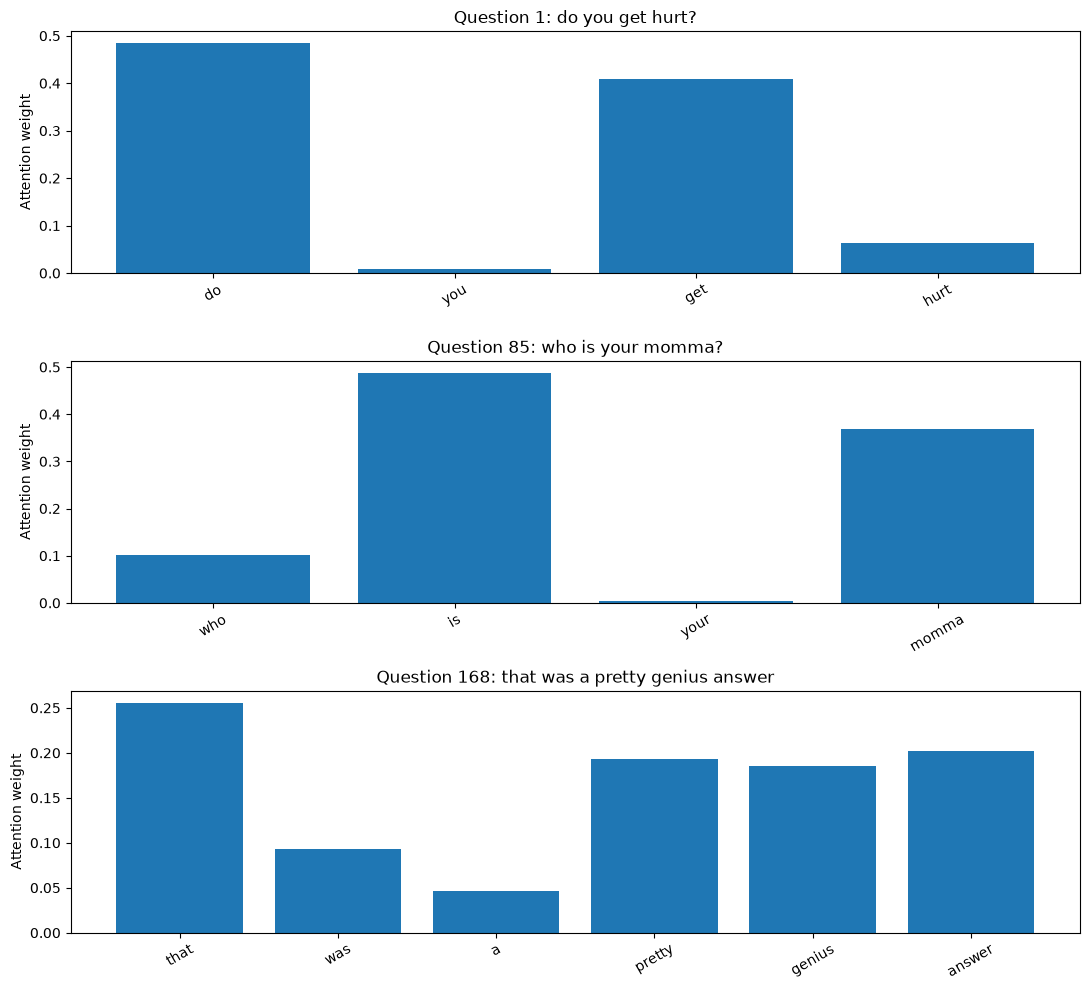

Task 1 answer: The most-attended word is not necessarily the most meaningful word.
If it is a topic-specific word, attention may be helping identify the question's intent.
If it is a common word, the model may be relying on patterns in this small training dataset.
I'm printing this after running it twice. As you can see from the graphs, the word with the highest attention in the first sentence is: do. for the 
second sentence: is. And for the third sentence: that.


In [19]:
model.eval()
indices = [0, len(df)//2, len(df)-1]
fig, axes = plt.subplots(3, 1, figsize=(11, 10))
for ax, idx in zip(axes, indices):
    tokens = X[idx][X[idx] != 0].tolist()
    words = tokenizer.sequences_to_texts([tokens])[0].split()
    with torch.no_grad():
        _, attention = model(X[idx:idx+1])
    scores = attention[0, :len(words)].cpu().numpy()
    highest = int(scores.argmax())
    ax.bar(words, scores)
    ax.set_title(f"Question {idx+1}: {df['question'].iloc[idx]}")
    ax.set_ylabel("Attention weight")
    ax.tick_params(axis="x", rotation=30)
    print(f"Question {idx+1}: {df['question'].iloc[idx]}")
    print(f"Highest-attention word: '{words[highest]}' (weight={scores[highest]:.4f})")
plt.tight_layout()
plt.show()
print("Task 1 answer: The most-attended word is not necessarily the most meaningful word.")
print("If it is a topic-specific word, attention may be helping identify the question's intent.")
print("If it is a common word, the model may be relying on patterns in this small training dataset.")
print("I'm printing this after running it twice. As you can see from the graphs, the word with the highest attention in the first sentence is: do. for the \nsecond sentence: is. And for the third sentence: that.")

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question 1: who are you?
Question 2: so how should i address you?
Highest-attention word for question 114: 'are'
Highest-attention word for question 122: 'should'


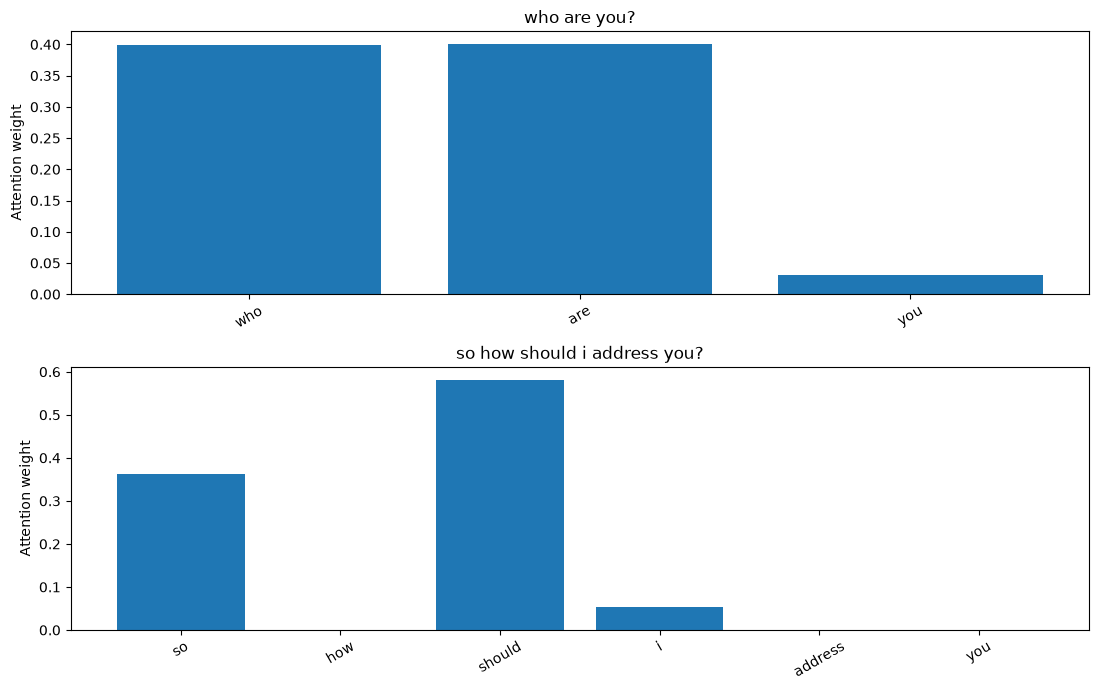

Task 2 answer:
The model emphasizes different words, which can still convey the same underlying intent.
Attention assigns context-dependent importance to tokens; it does not require identical wording.


In [18]:
from itertools import combinations
from difflib import SequenceMatcher

candidates = []
for answer_id, group in df.groupby("answer_id"):
    indices = group.index.tolist()
    for i, j in combinations(indices, 2):
        q1, q2 = str(df.loc[i, "question"]), str(df.loc[j, "question"])
        if q1 != q2:
            similarity = SequenceMatcher(None, q1, q2).ratio()
            candidates.append((similarity, i, j))
if not candidates:
    raise ValueError("No differently worded questions share an answer_id. Select a pair manually.")
_, i, j = min(candidates, key=lambda item: abs(item[0] - 0.55))
print("Question 1:", df.loc[i, "question"])
print("Question 2:", df.loc[j, "question"])

model.eval()
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
selected_words = []
for ax, idx in zip(axes, [i, j]):
    tokens = X[idx][X[idx] != 0].tolist()
    words = tokenizer.sequences_to_texts([tokens])[0].split()
    with torch.no_grad():
        logits, attention = model(X[idx:idx+1])
    scores = attention[0, :len(words)].cpu().numpy()
    top = words[int(scores.argmax())]
    selected_words.append(top)
    print(f"Highest-attention word for question {idx}: '{top}'")
    ax.bar(words, scores)
    ax.set_title(df.loc[idx, "question"])
    ax.set_ylabel("Attention weight")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
print("Task 2 answer:")
if selected_words[0] == selected_words[1]:
    print("The model emphasizes the same word in both questions, suggesting a shared clue to their intent.")
else:
    print("The model emphasizes different words, which can still convey the same underlying intent.")
print("Attention assigns context-dependent importance to tokens; it does not require identical wording.")
